# 01 · Base de conhecimento e busca (recall@1 e recall@3)

**Rota Livre** · Generative AI for Engineering · Global Solution 2026.2

Este notebook cobre os itens **02** (base de conhecimento em trechos com fonte) e
**03** (busca com recall@1 e recall@3 medidos e limiar justificado) da pontuação.

A tarefa da IA: **assistente do cidadão sobre buracos e obstáculos em vias e calçadas de São Paulo**
(mobilidade), respondendo com base em uma base de conhecimento com fontes oficiais
(CTB, Constituição, leis municipais, SP156) e recusando com "não consta" o que a base não cobre.

In [1]:
import sys, json
sys.path.append("..")
from src.busca import Busca, medir_recall, LIMIAR

busca = Busca()
casos = json.loads(open("../avaliacao/casos_teste.json", encoding="utf-8").read())["casos"]
print(f"{len(busca.trechos)} trechos na base · {len(casos)} casos de teste · limiar = {LIMIAR}")

36 trechos na base · 27 casos de teste · limiar = 0.15


## A base, em trechos com fonte

Cada trecho é curto, autocontido e tem `id`, `fonte` (lei/órgão) e `url`.

In [2]:
import pandas as pd
pd.set_option("display.max_colwidth", 90)
df_base = pd.DataFrame(busca.trechos)
df_base[["id", "fonte"]]

,id,fonte
0,ctb-01,"Lei Federal 9.503/1997 (CTB), art. 1º, §2º"
1,ctb-02,"Lei Federal 9.503/1997 (CTB), art. 1º, §3º"
2,ctb-03,"Lei Federal 9.503/1997 (CTB), art. 24"
3,ctb-04,"Lei Federal 9.503/1997 (CTB), art. 26"
4,ctb-05,"Lei Federal 9.503/1997 (CTB), art. 95, §1º"
5,cf-01,"Constituição Federal de 1988, art. 37, §6º"
6,jur-01,"Jurisprudência consolidada (ex.: TJMT, TJBA, TJDFT) sobre buracos em via pública"
7,cc-01,"Código Civil (Lei 10.406/2002), arts. 186 e 927"
8,presc-01,"Decreto Federal 20.910/1932, art. 1º"
9,ind-01,Prefeitura de São Paulo - pedido administrativo de indenização (reparação de danos)


## Exemplo de busca

In [3]:
for trecho, score in busca.buscar("caí num buraco, a prefeitura paga o prejuízo?"):
    print(f"{score:.3f}  [{trecho['id']}] {trecho['fonte']}")

0.175  [ind-01] Prefeitura de São Paulo - pedido administrativo de indenização (reparação de danos)
0.091  [sp156-01] Prefeitura de São Paulo - canais de atendimento SP156
0.084  [ind-03] Prefeitura de São Paulo - diferença entre reporte no SP156 e pedido de indenização


## recall@1 e recall@3

`recall@k` = fração dos casos **respondíveis** em que ao menos um trecho do gabarito
aparece entre os `k` primeiros resultados da busca TF-IDF.

In [4]:
r1 = medir_recall(busca, casos, k=1)
r3 = medir_recall(busca, casos, k=3)
print(f"recall@1 = {r1['recall']:.2%}  ({sum(d['acertou'] for d in r1['detalhes'])}/{r1['n_casos']})")
print(f"recall@3 = {r3['recall']:.2%}  ({sum(d['acertou'] for d in r3['detalhes'])}/{r3['n_casos']})")
erros = [d for d in r3["detalhes"] if not d["acertou"]]
print("casos errados no recall@3:", [d["id"] for d in erros] or "nenhum")

recall@1 = 95.45%  (21/22)
recall@3 = 100.00%  (22/22)
casos errados no recall@3: nenhum


## Justificativa do limiar de recusa

Abaixo, a distribuição do score top-1 das perguntas **respondíveis** vs **"não consta"**.
O limiar fica **abaixo do menor score respondível**: assim a busca nunca recusa uma pergunta
que a base cobre, e ainda barra "de graça" parte das perguntas sem resposta. As perguntas
sem resposta que passam do limiar são tratadas pela **regra de recusa no prompt** (RAG/agente).

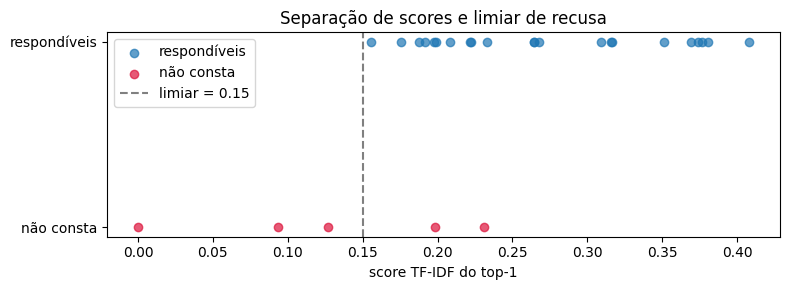

menor score respondível: 0.156
'não consta' barrados pelo limiar: 3/5


In [5]:
import matplotlib.pyplot as plt

scores_resp = [d["score_top1"] for d in r3["detalhes"]]
scores_nc = [busca.buscar(c["pergunta"], k=1)[0][1] for c in casos if c["tipo"] == "nao_consta"]

plt.figure(figsize=(8, 3))
plt.scatter(scores_resp, [1]*len(scores_resp), label="respondíveis", alpha=0.7)
plt.scatter(scores_nc, [0]*len(scores_nc), label="não consta", alpha=0.7, color="crimson")
plt.axvline(LIMIAR, ls="--", color="gray", label=f"limiar = {LIMIAR}")
plt.yticks([0, 1], ["não consta", "respondíveis"]); plt.xlabel("score TF-IDF do top-1")
plt.legend(); plt.title("Separação de scores e limiar de recusa"); plt.tight_layout()
plt.savefig("../avaliacao/limiar.png", dpi=120)
plt.show()
print(f"menor score respondível: {min(scores_resp):.3f}")
print(f"'não consta' barrados pelo limiar: {sum(s < LIMIAR for s in scores_nc)}/{len(scores_nc)}")